In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cmocean

import src.plotting as plot
import src.utils as utils
from src.config import *

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors

import cartopy.feature as cfeature
from shapely.geometry import Point
from scipy.interpolate import griddata


In [3]:
AMOC_ON = "pi/pi-amoc-on"
AMOC_OFF = "pi/pi-amoc-off"

## Comparison pi-amoc-on with pi-amoc-off

In [4]:
fpath = os.path.join(DIR_OUTPUT, AMOC_ON, 'atm.nc')
ds_atm_amoc_on = xr.open_dataset(fpath, mode='r')

fpath = os.path.join(DIR_OUTPUT, AMOC_OFF, 'atm.nc')
ds_atm_amoc_off = xr.open_dataset(fpath, mode='r')

fpath = os.path.join(DIR_OUTPUT, AMOC_ON, 'sic.nc')
ds_sic_amoc_on = xr.open_dataset(fpath, mode='r')

fpath = os.path.join(DIR_OUTPUT, AMOC_OFF, 'sic.nc')
ds_sic_amoc_off = xr.open_dataset(fpath, mode='r')

In [5]:
def plot_ATM_GIS(
    ds_atm, scenario, ds_atm_control=None, fig=None, ax=None, var="t2a", var_label="t2a_diff",
    month_inds=[5, 6, 7], season="summer",
    cmap=plt.get_cmap('Blues_r'), vmin=-20, vmax=0, n_levels=21, extend=None, 
    year_slice=slice(0, 1), plot_cbar=True, cbar_left=False, savefig=False
):
    if ax is None:
        fig, ax = plot.subplots_GIS()

    var_labels = [
        "t2a", "t2a_diff", "prc", "prc_diff", "prcs", "prcs_diff"
    ]
    cbar_labels = {
        "t2a": r"Temperature ($\!^\circ\!\mathrm{C}$)",#\n$_{\\text{(AMOC off - AMOC on)}}$",
        "t2a_diff": r"Temperature anomaly ($\!^\circ\!\mathrm{C}$)",#\n$_{\\text{(AMOC off - AMOC on)}}$",
        "prc": "Precipitation (kg/m$^2$/day)",
        "prc_diff": "Precipitation anomaly (kg/m$^2$/day)",
        "prcs": "Snowfall (kg/m$^2$/day)",
        "prcs_diff": "Snowfall anomaly (kg/m$^2$/day)",
    }
    if var_label not in var_labels:
        raise ValueError(f"Colorbar label '{var_label}' not recognized. Use one of {var_labels}.")

    # Average over the specified months
    ds_plot = ds_atm[var]
    ds_plot = ds_plot.isel(mon=month_inds).mean(dim='mon')
    ds_plot = ds_plot.isel(time=year_slice).mean(dim='time')

    if ds_atm_control is not None:
        ds_plot_control = ds_atm_control[var]
        ds_plot_control = ds_plot_control.isel(mon=month_inds).mean(dim='mon')
        ds_plot_control = ds_plot_control.isel(time=year_slice).mean(dim='time')

        print(f"Total difference in {season} temperature (K): {(ds_plot - ds_plot_control).mean(dim=["lat", "lon"]).values}")

        # Calculate the difference
        ds_plot = ds_plot - ds_plot_control
    else:
        if "t2a" in var:
            ds_plot = ds_plot - 273.15

    # Print approximate min and max values of the dataset
    extent = ax.get_extent(crs=ccrs.PlateCarree())
    ds_min = ds_plot.sel(lat=slice(extent[2], extent[3]), lon=slice(extent[0], extent[1])).min()
    ds_max = ds_plot.sel(lat=slice(extent[2], extent[3]), lon=slice(extent[0], extent[1])).max()
    print(f"{scenario} {season} {var_label} min: {ds_min.values}, max: {ds_max.values}")

    # Set minimum value for the colormap and plot
    levels = np.linspace(vmin, vmax, n_levels)

    # Plot with norm from min negative to 0 (normal linear normalization)
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    data = ds_plot.values
    lon = ds_plot.lon.values
    lat = ds_plot.lat.values

    cf = ax.contourf(
        lon, lat, data, levels=levels, cmap=cmap, norm=norm, extend=extend,
        transform=ccrs.PlateCarree()
    )

    if plot_cbar:
        from mpl_toolkits.axes_grid1.inset_locator import inset_axes

        if cbar_left:
            bbox_to_anchor=(-0.15, 0, 0.15, 1)
            loc = "lower left"
        else: # cbar on the right
            bbox_to_anchor=(1, 0, 0.15, 1)
            loc="lower right"
        cax = inset_axes(
            ax,
            width="55%",
            height="100%",
            loc=loc,
            bbox_to_anchor=bbox_to_anchor,
            bbox_transform=ax.transAxes,
            borderpad=0,
        )

        cbar = plt.colorbar(cf, cax=cax)
        if cbar_left:
            cbar.ax.yaxis.set_ticks_position("left")
            cbar.ax.yaxis.set_label_position("left")
        cbar.set_label(cbar_labels[var_label], fontsize=6)

    else:
        cbar = None

    ax.coastlines(resolution='110m', zorder=20, linewidth=0.5)

    if savefig:
        fig.savefig(os.path.join(DIR_FIG, f"{scenario}_{season}_{var_label}.png"), dpi=300)

    return fig, ax, cf, cbar

## Difference in pre-industrial snowfall and temperature above Greenland

In [6]:
# Pre-select regional box around Greenland
ds_atm_amoc_on_subset = ds_atm_amoc_on.sel(lat=slice(55, 86), lon=slice(-75, -5))
ds_atm_amoc_off_subset = ds_atm_amoc_off.sel(lat=slice(55, 86), lon=slice(-75, -5))

# Select only variables of interest
vars = ["t2a", "prc", "prcw", "prcs"]
ds_atm_amoc_on_subset = ds_atm_amoc_on_subset[vars]
ds_atm_amoc_off_subset = ds_atm_amoc_off_subset[vars]

lon, lat = ds_atm_amoc_on_subset.lon, ds_atm_amoc_on_subset.lat
mask_da = utils.create_grl_atm_mask(lon, lat)

# Apply mask
ds_atm_amoc_on_subset_masked = ds_atm_amoc_on_subset.where(mask_da)
ds_atm_amoc_off_subset_masked = ds_atm_amoc_off_subset.where(mask_da)

# Calculate difference (amoc off - amoc on)
ds_atm_amoc_diff_subset = ds_atm_amoc_off_subset_masked - ds_atm_amoc_on_subset_masked

### Data for table

In [7]:
# Calculate average yearly change in temp and precip averaged over domain and all 1000 years
# Weighted by latitude (cosine of latitude)
weights = xr.DataArray(
    np.cos(np.deg2rad(ds_atm_amoc_diff_subset.lat)),
    coords={"lat": ds_atm_amoc_diff_subset.lat},
    dims=["lat"],
)

for var in vars:
    print(f"Calculating changes in {var}...")
    yearly_amoc_on = (
        ds_atm_amoc_on_subset_masked[var]
        .isel(mon=12)
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])
    )
    yearly_amoc_off = (
        ds_atm_amoc_off_subset_masked[var]
        .isel(mon=12)
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])       
    )
    diff_yearly = (
        ds_atm_amoc_diff_subset[var]
        .isel(mon=12)
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])
    )
    if "t2a" in var:
        yearly_amoc_on = yearly_amoc_on - 273.15
        yearly_amoc_off = yearly_amoc_off - 273.15
    print(f"Yearly average AMOC-on in {var}: {yearly_amoc_on:.2f}")
    print(f"Yearly average AMOC-off in {var}: {yearly_amoc_off:.2f}")
    print(f"Average yearly change in {var}: {diff_yearly.values:.2f}")
    print("")


    summer_amoc_on = (
        ds_atm_amoc_on_subset_masked[var]
        .isel(mon=[5, 6, 7])
        .mean(dim="mon")
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])
    )
    summer_amoc_off = (
        ds_atm_amoc_off_subset_masked[var]
        .isel(mon=[5, 6, 7])
        .mean(dim="mon")
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])       
    )
    diff_summer = (
        ds_atm_amoc_diff_subset[var]
        .isel(mon=[5, 6, 7])
        .mean(dim="mon")
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])
    )
    if "t2a" in var:
        summer_amoc_on = summer_amoc_on - 273.15
        summer_amoc_off = summer_amoc_off - 273.15
    print(f"Summer average AMOC-on in {var}: {summer_amoc_on:.2f}")
    print(f"Summer average AMOC-off in {var}: {summer_amoc_off:.2f}")
    print(f"Average summer change in {var}: {diff_summer.values:.2f}")
    print("")

    winter_amoc_on = (
        ds_atm_amoc_on_subset_masked[var]
        .isel(mon=[11, 0, 1])
        .mean(dim="mon")
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])
    )
    winter_amoc_off = (
        ds_atm_amoc_off_subset_masked[var]
        .isel(mon=[11, 0, 1])
        .mean(dim="mon")
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])       
    )
    diff_winter = (
        ds_atm_amoc_diff_subset[var]
        .isel(mon=[11, 0, 1])
        .mean(dim="mon")
        .mean(dim="time")
        .weighted(weights)
        .mean(dim=["lat", "lon"])
    )
    if "t2a" in var:
        winter_amoc_on = winter_amoc_on - 273.15
        winter_amoc_off = winter_amoc_off - 273.15
    print(f"Winter average AMOC-on in {var}: {winter_amoc_on:.2f}")
    print(f"Winter average AMOC-off in {var}: {winter_amoc_off:.2f}")
    print(f"Average winter change in {var}: {diff_winter.values:.2f}")
    print("\n")


Calculating changes in t2a...
Yearly average AMOC-on in t2a: -21.36
Yearly average AMOC-off in t2a: -26.35
Average yearly change in t2a: -4.98

Summer average AMOC-on in t2a: -5.29
Summer average AMOC-off in t2a: -7.53
Average summer change in t2a: -2.24

Winter average AMOC-on in t2a: -33.54
Winter average AMOC-off in t2a: -41.60
Average winter change in t2a: -8.07


Calculating changes in prc...
Yearly average AMOC-on in prc: 0.95
Yearly average AMOC-off in prc: 0.56
Average yearly change in prc: -0.39

Summer average AMOC-on in prc: 1.10
Summer average AMOC-off in prc: 0.92
Average summer change in prc: -0.18

Winter average AMOC-on in prc: 0.93
Winter average AMOC-off in prc: 0.30
Average winter change in prc: -0.63


Calculating changes in prcw...
Yearly average AMOC-on in prcw: 0.09
Yearly average AMOC-off in prcw: 0.04
Average yearly change in prcw: -0.05

Summer average AMOC-on in prcw: 0.31
Summer average AMOC-off in prcw: 0.16
Average summer change in prcw: -0.15

Winter aver

### Greenland mask

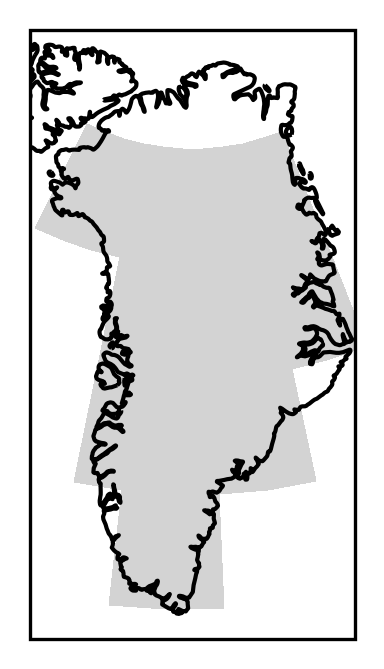

In [8]:
# Plot mask used
fig, ax = plot.subplots_GIS()
# Create a cmap with just a single grey colour to plot the mask
cmap = mcolors.ListedColormap(['lightgrey'])
ax.pcolormesh(ds_atm_amoc_diff_subset.lon, ds_atm_amoc_diff_subset.lat,
              ds_atm_amoc_diff_subset["t2a"].isel(time=0, mon=12), transform=ccrs.PlateCarree(), cmap=cmap)
ax.add_feature(cfeature.COASTLINE)
ax.set_title('')

plt.savefig(os.path.join(DIR_FIG, 'atm_mask.pdf'))

### Anomalies plotted above Greenland

Total difference in summer temperature (K): 0.5864564776420593
pi-amoc-off-minus-on summer t2a_diff min: -8.910491943359375, max: -0.858154296875
Total difference in winter temperature (K): -1.5136594772338867
pi-amoc-off-minus-on winter t2a_diff min: -26.756729125976562, max: -3.7539520263671875
Total difference in summer temperature (K): -0.01722126267850399
pi-amoc-off-minus-on summer prcs_diff min: -0.3556783199310303, max: 0.77860426902771
Total difference in winter temperature (K): -0.04189077764749527
pi-amoc-off-minus-on winter prcs_diff min: -4.796201705932617, max: 0.374625563621521


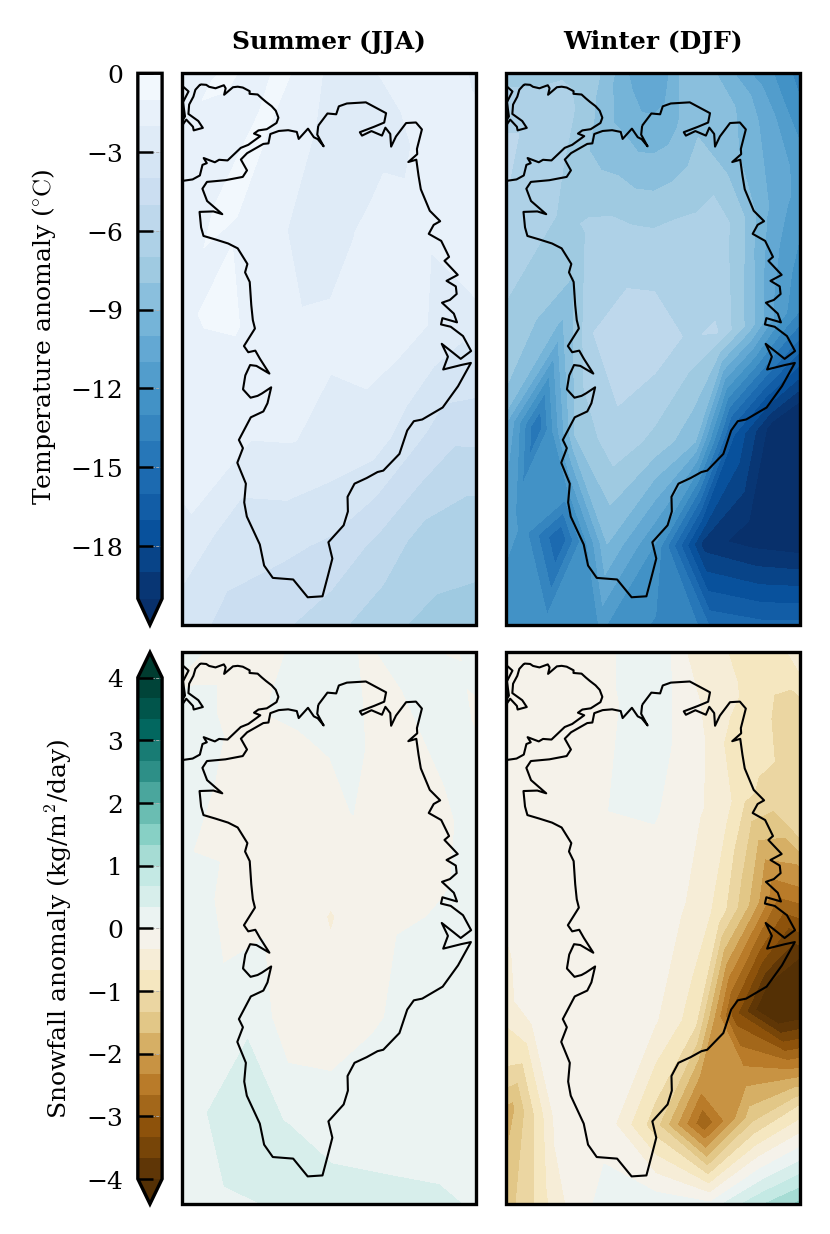

In [9]:
### Compare GIS atmosphere at preindustrial CO2 levels

# Months to average over
# Summer: JJA [5, 6, 7]
# Winter: DJF [11, 0, 1]
seasons = {
    "summer": [5, 6, 7],
    "winter": [11, 0, 1],
}

fig, axs = plot.subplots_GIS(nrows=2, ncols=2, figsize=(plot.width_onecol*0.86, 1.1*plot.height_twocol), constrained_layout=False)
axs = axs.flatten()

# Adjust by reducing wspace and hspace
fig.subplots_adjust(wspace=-0.1, hspace=0.05)

# Temperature anomaly
_, _, cf_temp, _ = plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-off-minus-on", ds_atm_control=ds_atm_amoc_on, month_inds=seasons["summer"], 
    season="summer", var="t2a", var_label="t2a_diff", extend="min",
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[0], plot_cbar=True, cbar_left=True
)

plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-off-minus-on", ds_atm_control=ds_atm_amoc_on, month_inds=seasons["winter"], 
    season="winter", var="t2a", var_label="t2a_diff", extend="min",
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[1], plot_cbar=False
)

### Precipitation anomaly
_, _, cf_snow, _ = plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-off-minus-on", ds_atm_control=ds_atm_amoc_on, month_inds=seasons["summer"], 
    season="summer", var="prcs", var_label="prcs_diff", extend="both", vmin=-4, vmax=4, n_levels=25, cmap=plt.get_cmap("BrBG"),
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[2], plot_cbar=True, cbar_left=True
)

plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-off-minus-on", ds_atm_control=ds_atm_amoc_on, month_inds=seasons["winter"], 
    season="winter", var="prcs", var_label="prcs_diff", extend="both", vmin=-4, vmax=4, n_levels=25, cmap=plt.get_cmap("BrBG"),
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[3], plot_cbar=False
)

axs[0].set_title("Summer (JJA)", fontweight='bold', fontsize=6)
axs[1].set_title("Winter (DJF)", fontweight='bold', fontsize=6)

plt.savefig(os.path.join(DIR_FIG, "ATM_GIS_comparison.pdf"), format="pdf", bbox_inches="tight")

pi-amoc-on summer t2a min: -14.336700439453125, max: 12.638275146484375
pi-amoc-on winter t2a min: -46.105316162109375, max: 0.7203369140625
pi-amoc-on summer t2a min: -15.88104248046875, max: 9.663787841796875
pi-amoc-on winter t2a min: -52.75511169433594, max: -22.196609497070312


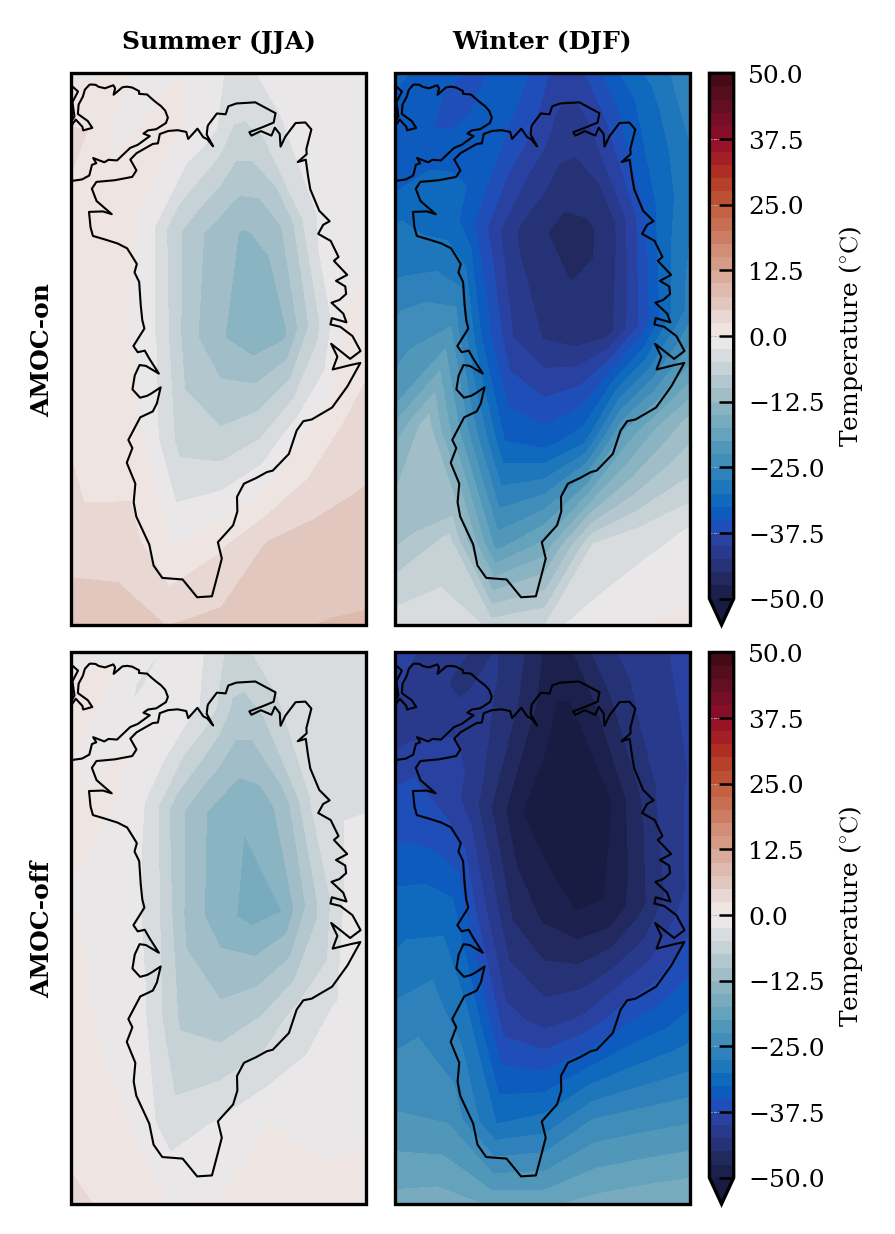

In [10]:
### Compare GIS atmosphere at preindustrial CO2 levels
# Absolute summer and winter temperatures

# Months to average over
# Summer: JJA [5, 6, 7]
# Winter: DJF [11, 0, 1]
seasons = {
    "summer": [5, 6, 7],
    "winter": [11, 0, 1],
}

fig, axs = plot.subplots_GIS(nrows=2, ncols=2, figsize=(plot.width_onecol*0.86, 1.1*plot.height_twocol), constrained_layout=False)
axs = axs.flatten()

# Adjust by reducing wspace and hspace
fig.subplots_adjust(wspace=-0.1, hspace=0.05)

vmin = -50
vmax = 50
cmap = cmocean.cm.balance
n_levels = 41

# Temperature anomaly
_, _, cf_temp, _ = plot_ATM_GIS(
    ds_atm_amoc_on, "pi-amoc-on", month_inds=seasons["summer"], 
    season="summer", var="t2a", var_label="t2a", extend="min", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[0], plot_cbar=False
)

plot_ATM_GIS(
    ds_atm_amoc_on, "pi-amoc-on", month_inds=seasons["winter"], 
    season="winter", var="t2a", var_label="t2a", extend="min", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[1], plot_cbar=True
)

_, _, cf_temp, _ = plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-on", month_inds=seasons["summer"], 
    season="summer", var="t2a", var_label="t2a", extend="min", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[2], plot_cbar=False
)

plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-on", month_inds=seasons["winter"], 
    season="winter", var="t2a", var_label="t2a", extend="min", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[3], plot_cbar=True
)

axs[0].set_title("Summer (JJA)", fontweight='bold', fontsize=6)
axs[1].set_title("Winter (DJF)", fontweight='bold', fontsize=6)

# Add AMOC-on and AMOC-off text to left side of figure
axs[0].text(-0.1, 0.5, "AMOC-on", va='center', ha='center', rotation='vertical', transform=axs[0].transAxes, fontweight='bold', fontsize=6)
axs[2].text(-0.1, 0.5, "AMOC-off", va='center', ha='center', rotation='vertical', transform=axs[2].transAxes, fontweight='bold', fontsize=6)

plt.savefig(os.path.join(DIR_FIG, "ATM_GIS_temperature.pdf"), format="pdf", bbox_inches="tight")

pi-amoc-on summer prcs min: 0.0, max: 2.2087056636810303
pi-amoc-on winter prcs min: 0.009591348469257355, max: 5.776501178741455
pi-amoc-on summer prcs min: 0.004755495116114616, max: 1.9565074443817139
pi-amoc-on winter prcs min: 0.0031139380298554897, max: 2.1864748001098633


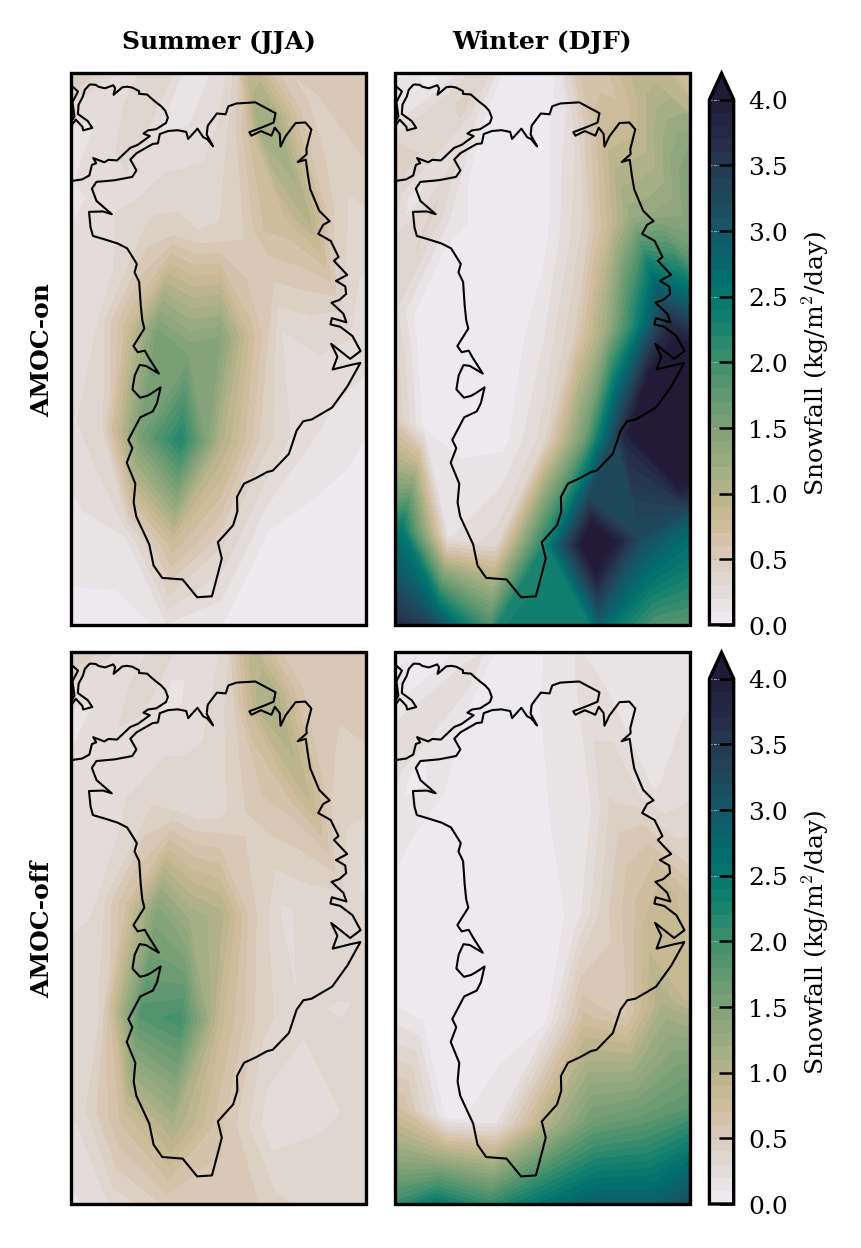

In [11]:
### Compare GIS atmosphere at preindustrial CO2 levels
# Absolute summer and winter snowfall

# Months to average over
# Summer: JJA [5, 6, 7]
# Winter: DJF [11, 0, 1]
seasons = {
    "summer": [5, 6, 7],
    "winter": [11, 0, 1],
}

fig, axs = plot.subplots_GIS(nrows=2, ncols=2, figsize=(plot.width_onecol*0.86, 1.1*plot.height_twocol), constrained_layout=False)
axs = axs.flatten()

# Adjust by reducing wspace and hspace
fig.subplots_adjust(wspace=-0.1, hspace=0.05)

vmin = 0
vmax = 4
n_levels = 17
n_levels = 41
# cmap = cmocean.cm.balance
cmap = cmocean.cm.rain
# colors = cmap(np.linspace(0, 1, 256))  # take only 0-0.5 range
# trunc_cmap = mcolors.LinearSegmentedColormap.from_list('trunc_blues', colors)

# Snowfall 
_, _, cf_temp, _ = plot_ATM_GIS(
    ds_atm_amoc_on, "pi-amoc-on", month_inds=seasons["summer"], 
    season="summer", var="prcs", var_label="prcs", extend="max", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[0], plot_cbar=False
)

plot_ATM_GIS(
    ds_atm_amoc_on, "pi-amoc-on", month_inds=seasons["winter"], 
    season="winter", var="prcs", var_label="prcs", extend="max", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[1], plot_cbar=True
)

_, _, cf_temp, _ = plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-on", month_inds=seasons["summer"], 
    season="summer", var="prcs", var_label="prcs", extend="max", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[2], plot_cbar=False
)

plot_ATM_GIS(
    ds_atm_amoc_off, "pi-amoc-on", month_inds=seasons["winter"], 
    season="winter", var="prcs", var_label="prcs", extend="max", vmin=vmin, vmax=vmax, cmap=cmap, n_levels=n_levels,
    year_slice=slice(0, 1000), savefig=False, fig=fig, ax=axs[3], plot_cbar=True
)

axs[0].set_title("Summer (JJA)", fontweight='bold', fontsize=6)
axs[1].set_title("Winter (DJF)", fontweight='bold', fontsize=6)

# Add AMOC-on and AMOC-off text to left side of figure
axs[0].text(-0.1, 0.5, "AMOC-on", va='center', ha='center', rotation='vertical', transform=axs[0].transAxes, fontweight='bold', fontsize=6)
axs[2].text(-0.1, 0.5, "AMOC-off", va='center', ha='center', rotation='vertical', transform=axs[2].transAxes, fontweight='bold', fontsize=6)

plt.savefig(os.path.join(DIR_FIG, "ATM_GIS_snowfall.pdf"), format="pdf", bbox_inches="tight")